In [1]:
# Add the root path of the pyqula library
import os ; import sys
try: sys.path.append(os.environ["PYQULAROOT"]) # add the library via environmental variable
except: pass
try: from pyqula import geometry # check if the library is present
except: # pyqula not installed
    print("pyqula needs to be installed, installing it")
    import subprocess ; subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade","pyqula"])

# some default parameters in matplotlib
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [20, 8]
plt.rcParams['font.size'] = 22
plt.rcParams['image.cmap'] = 'coolwarm'


import numpy as np

# Advanced Quantum Materials, session 6: Classical magnetism and magnons
In this session we will address several systems featuring magnetism, and understand their origin

### Contents
- Symmetry breaking by magnetic interactions
- The strong coupling limit of a magnetic system
- Intermediate coupling regime and Stoner instability
- Non-collinear magnetism from competing interactions
- Non-collinear magnetism from spin-orbit coupling
- Non-collinear magnetism from magnetic frustration
- Topological magnons in 2D magnets
- Many-body spin response functions and their relation to magnons

### Learning outcomes
- Understand the impact of electronic repulsion in an electronic structure
- Rationalize the intermediate and strong coupling regimes of an interacting magnetic system
- Understand mechanisms leading to non-collinear magnetism

### About the exercises
The notebooks contain three types of exercises, with each exercise containing **Quiz** questions to answer
- ***Reminder***: brief recall from previous sessions, you can skip it if you remember it
- ***Core***: basic exercises you should understand in each session
- ***Challenge***: advanced exercises to dive deeper into concepts, not necessary to understand in full in each session

### It is not necessary to complete all the exercises, you can just focus on those that sound most interesting for you.

## Bandstructure of a tight binding chain with two sites (***Reminder***)
We will start showing the magnetic instabilities of a 1D chain at half filling, with two sites per unit cell

As in session 2, doubling the unit cell to two sites folds the single chain band $E(k)=2t\cos k$ into two branches on the halved Brillouin zone — purely a change of unit cell, with the same physics as the single-site chain. This two-site cell is the natural starting point for antiferromagnetic order, which needs two sublattices to describe.

([], [])

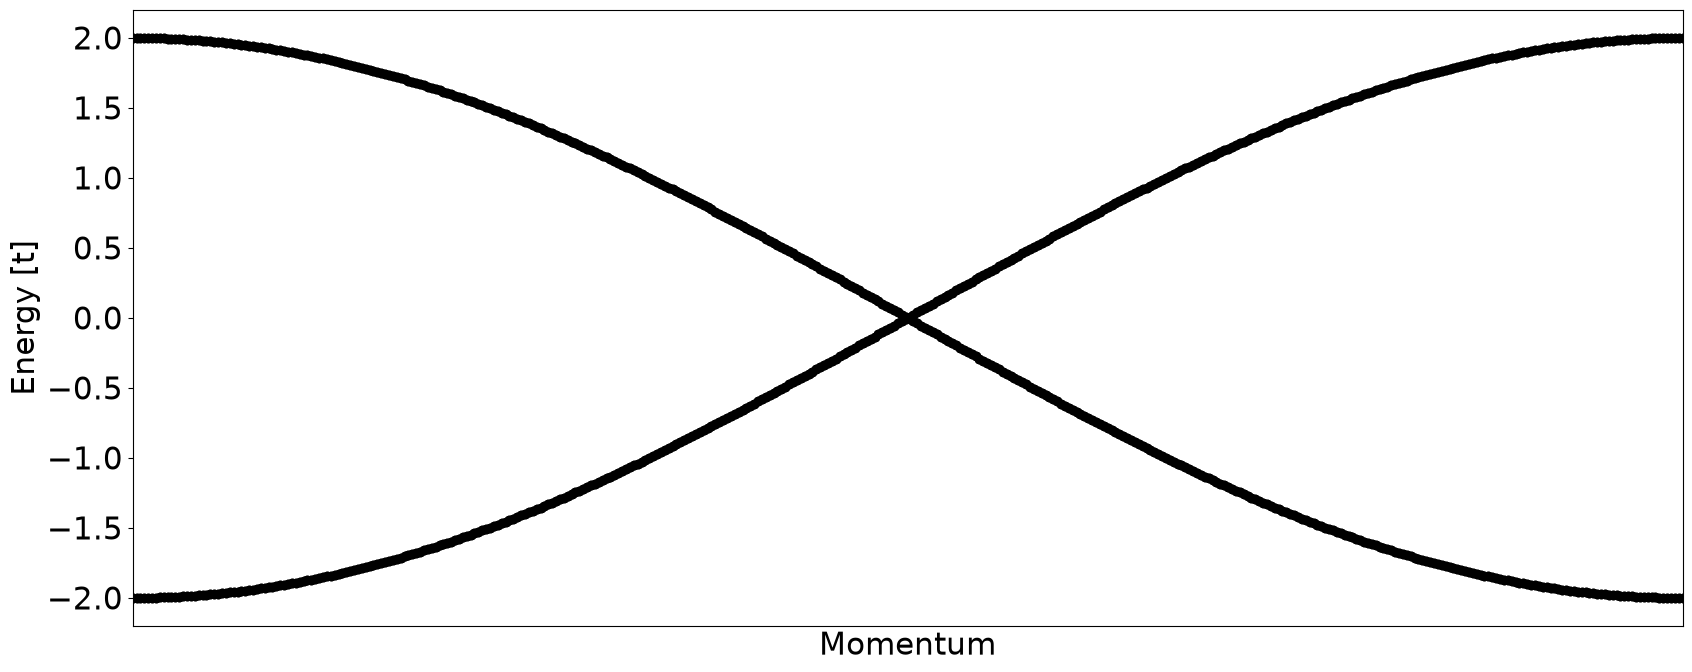

In [2]:
from pyqula import geometry
g = geometry.chain() # generate a chain
NS = 2 # size of the supercell
g = g.get_supercell(NS) # make a supercell
h = g.get_hamiltonian() # generate the Hamiltonian
(k,e) = h.get_bands() # compute band structure
plt.xlim([min(k),max(k)]) # adjust plot
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]") ; plt.xticks([]) # plot

### Quiz
- Discuss why there are two bands in this chain
- Change the size of the supercell, how many bands do you have and why?

## Magnetic order driven by interactions in a chain (***Core***)

As in session 1, the Hubbard interaction $U n_{i\uparrow}n_{i\downarrow}$ is decoupled at the mean-field level into an effective potential set by the local magnetization $\langle S_z\rangle_i = \tfrac12(\langle n_{i\uparrow}\rangle-\langle n_{i\downarrow}\rangle)$. Ferromagnetic and antiferromagnetic initial guesses converge to different self-consistent solutions; comparing their total energies decides which one is the true ground state.

(np.float64(-3.85),
 np.float64(3.85),
 np.float64(-0.05500000000000001),
 np.float64(0.05500000000000001))

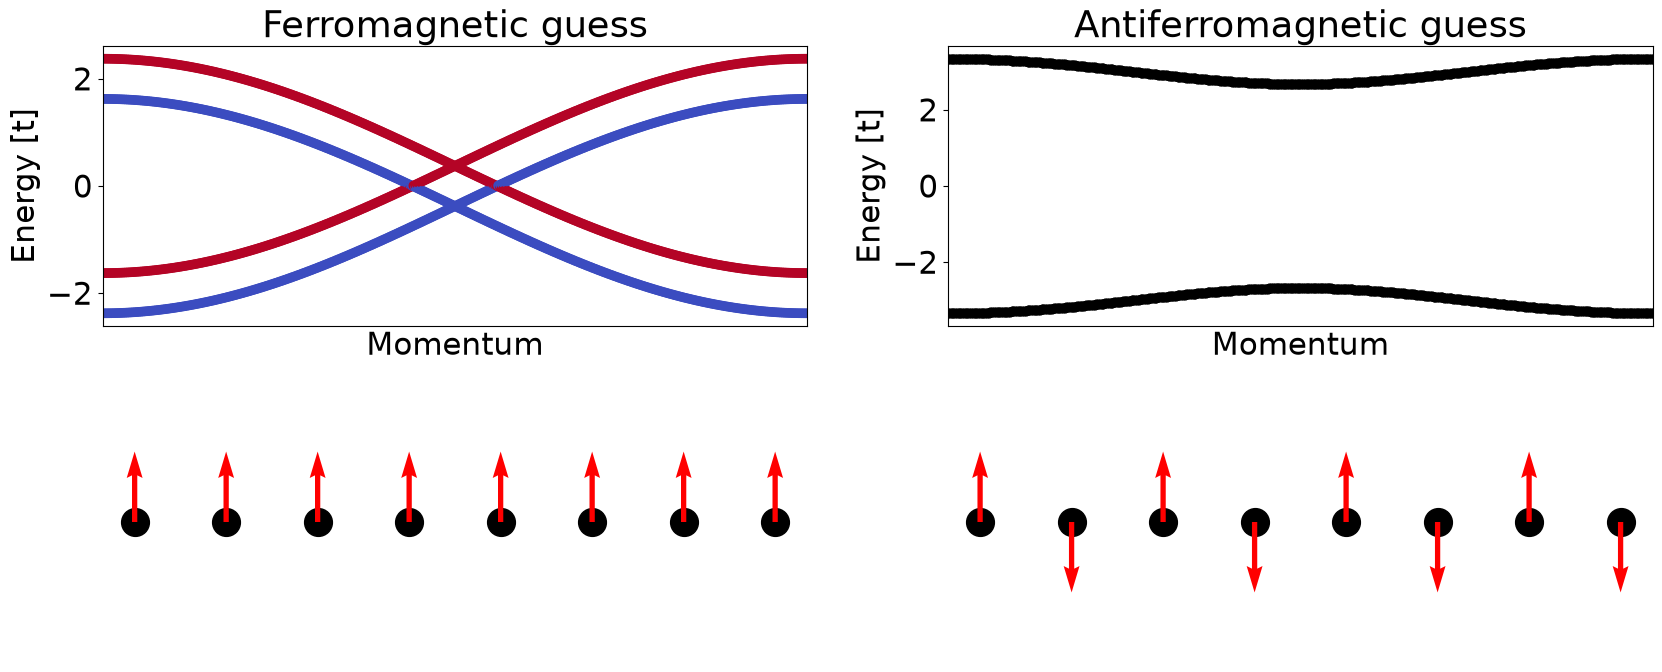

In [3]:
# let us now add interactions, and compute the electronic structure
from pyqula import geometry
g = geometry.bichain() # generate a chain with two sites per unit cell (with internal sublattice)
h = g.get_hamiltonian() # generate the Hamiltonian

U = 6.0 # value of the local interaction

# first with a ferromagnetic guess
plt.subplot(2,2,1)
plt.title("Ferromagnetic guess")
hfe = h.get_mean_field_hamiltonian(U=U,mf="ferro") # solve the interacting problem with a mean-field guess
(k,e,c) = hfe.get_bands(operator="sz") # compute band structure
plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]") ; plt.xticks([]) 
plt.xlim([min(k),max(k)]) # plot

# plot magnetization
hs = hfe.get_supercell(4) ; gs = hs.geometry ; mz = hs.extract("mz") # supercell geometry and Mz
plt.subplot(2,2,3)
x = gs.r[:,0] ; y = gs.r[:,1] 
mz = mz/np.max(np.abs(mz)) # normalize
plt.scatter(x,y,c="black",s=400) ; plt.quiver(x,y,0.,mz,color="red",scale=10) ; plt.axis("off") ; plt.axis("equal") # plot

# and with an antiferromagnetic guess
plt.subplot(2,2,2)
plt.title("Antiferromagnetic guess")
haf = h.get_mean_field_hamiltonian(U=U,mf="antiferro") # solve the interacting problem with a mean-field guess
(k,e) = haf.get_bands() # compute band structure
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]") ; plt.xticks([]) 
plt.xlim([min(k),max(k)]) # plot

# plot magnetization
hs = haf.get_supercell(4) ; gs = hs.geometry ; mz = hs.extract("mz") # supercell geometry and Mz
plt.subplot(2,2,4)
x = gs.r[:,0] ; y = gs.r[:,1] 
mz = mz/np.max(np.abs(mz)) # normalize
plt.scatter(x,y,c="black",s=400) ; plt.quiver(x,y,0.,mz,color="red",scale=10) ; plt.axis("off") ; plt.axis("equal") # plot

### Quiz
- Discuss which solution you think it has the lowest energy, and why
- Compute the selfconsistent solution for stronger values of the interaction. Which change do you observe?

## The spectra of a dimer (***Reminder***)
Here we will review the electronic spectra of a tight binding dimer

Two sites connected by a hopping $t$ are described by $H=\begin{pmatrix}0&t\\t&0\end{pmatrix}$, with bonding/antibonding eigenstates at $E=\pm t$; including spin trivially doubles every level, giving four eigenstates for two sites.

Text(0.5, 0, 'State index')

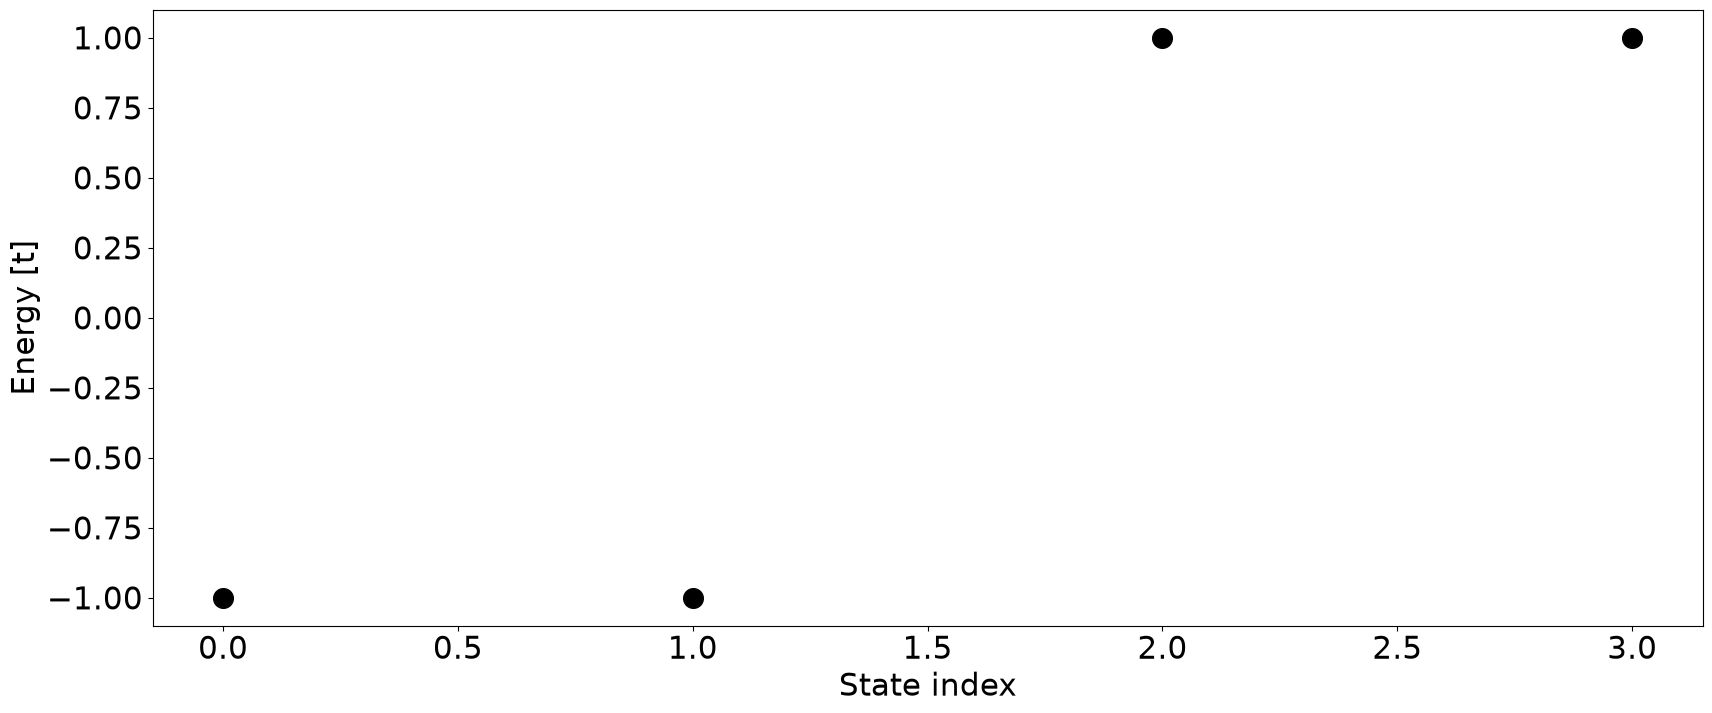

In [4]:
from pyqula import geometry
g = geometry.bichain() # generate a chain with two sites per unit cell (with internal sublattice)
g.dimensionality = 0 # just retain the two sites per unit cell


h = g.get_hamiltonian(has_spin=True) # generate Hamiltonian

(ks,es) = h.get_bands() # get bands
plt.scatter(range(len(es)),es,c="black",s=200) ; plt.ylabel("Energy [t]") ; plt.xlabel("State index")

### Quiz
- There are two sites in the system, why do we have four eigenstates?
- Why are the states degenerate in energy?

## The interacting Hubbard dimer (***Core***)
Here we will see how the magnetization evolves in an interacting dimer chain

The same mean-field decoupling applied to two sites yields a magnetization $\langle S_z\rangle(U)$ that stays zero below a critical interaction and grows continuously above it — a mean-field analogue of the Stoner criterion — saturating towards $\langle S_z\rangle=1/2$ per site in the strongly interacting limit.

Text(0, 0.5, '$\\langle S_z \\rangle $')

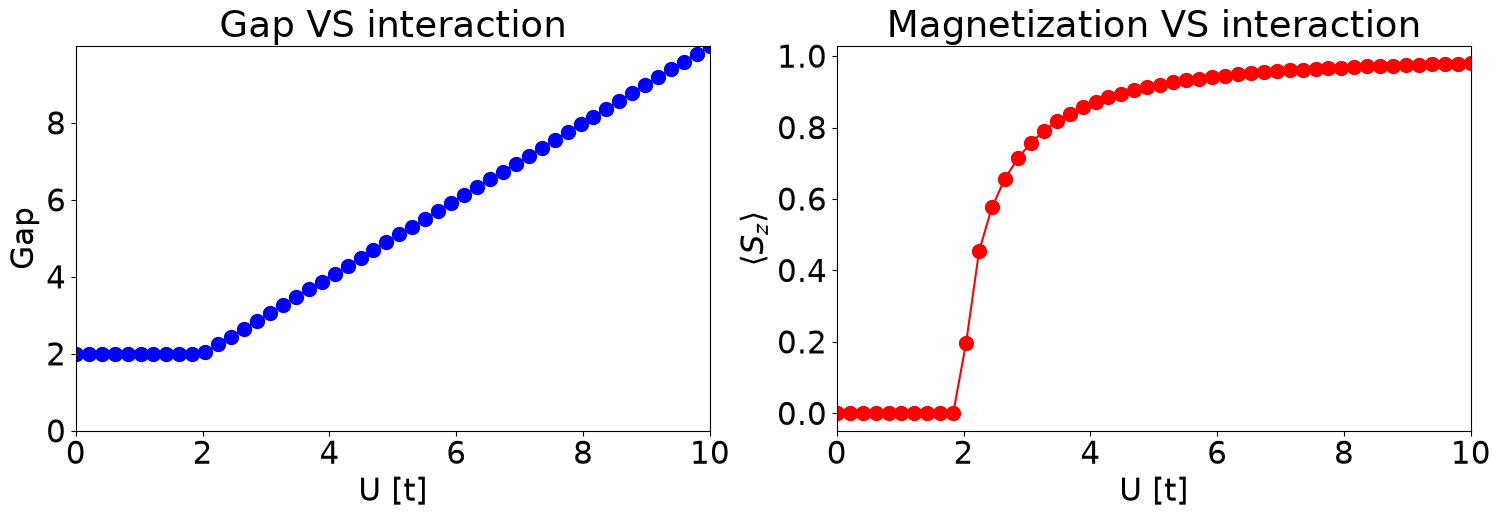

In [5]:
from pyqula import geometry
g = geometry.bichain() # generate a chain with two sites per unit cell (with internal sublattice)
L = 1 # size of the system
g = g.get_supercell(L) # make a supercell
g.dimensionality = 0 # just retain the two sites per unit cell
h0 = g.get_hamiltonian() # generate the Hamiltonian

Us = np.linspace(0.,10.,50) # interaction values
mzs = [] # empty list for magnetizations
gaps = [] # gaps of the systems
for U in Us:
    h = h0.get_mean_field_hamiltonian(U=U,mf="antiferro",mix=0.9) # perform SCF
    mz = h.get_vev("mz")[1] # magnetization of the second site
    mzs.append(abs(mz)) # store magnetization in that size
    gaps.append(h.get_gap()) # compute gap of the system and store it


plt.figure(figsize=(18,5))

plt.subplot(1,2,1) # plot the magnetization VS interaction
plt.title("Gap VS interaction")
plt.plot(Us,gaps,marker="o",c="blue",markersize=10) ; plt.xlim([min(Us),max(Us)])
plt.xlabel("U [t]") ; plt.ylabel("Gap") ; plt.ylim([0,max(gaps)])

plt.subplot(1,2,2) # plot the magnetization VS interaction
plt.title("Magnetization VS interaction")
plt.plot(Us,mzs,marker="o",c="red",markersize=10) ; plt.xlim([min(Us),max(Us)])
plt.xlabel("U [t]") ; plt.ylabel("$\\langle S_z \\rangle $")

### Quiz
- Identify the non-interacting limit in the plot
- Identify the strongly interacting limit in the plot
- Why does the magnetization saturate at large interactions?
- Why is there a critical value to have magnetization?

## Gap opening in the Hubbard model (***Core***)
We will now see how the Hubbard interaction give rise to a gap opening in an interacting chain

As in the 1D Hubbard chain of session 1, the converged antiferromagnetic order acts as a staggered onsite potential $\pm Um/2$ (with $m$ the local moment), opening a gap $E_g\approx Um$ that grows with the interaction strength.

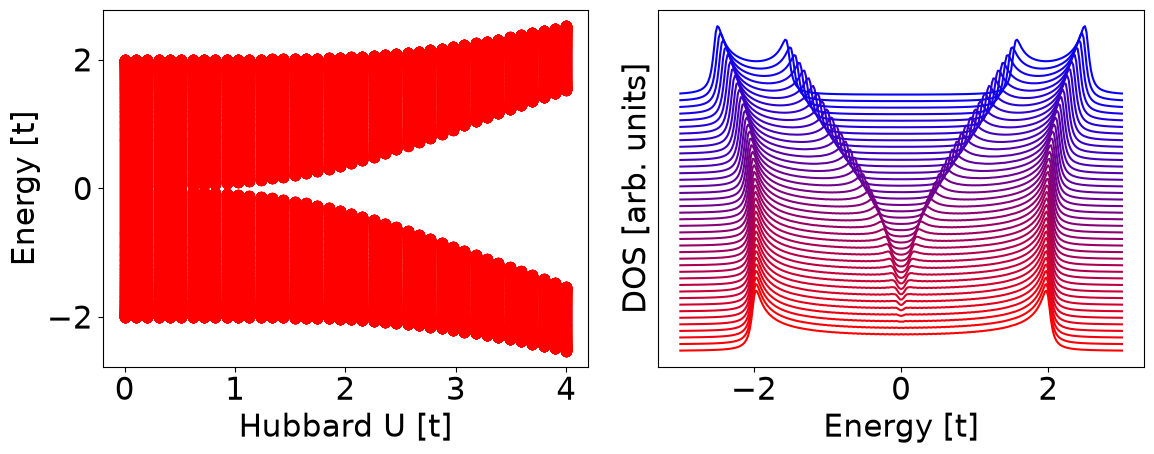

In [6]:
fig = plt.figure(figsize=(12,5))

Us = np.linspace(0.,4.0,40)

g = geometry.bichain() # generate a chain
h0 = g.get_hamiltonian() # generate the Hamiltonian
iU = 0 # counter
for U in Us:
    h = h0.get_mean_field_hamiltonian(U=U,mf="antiferro",mix=0.9) # perform SCF
#    h = h0.get_mean_field_hamiltonian(U=U,mf="ferro",mix=0.9) # perform SCF, with a ferromagnetic initialization
    (k,e) = h.get_bands() # compute band structure
    edos = np.linspace(-3,3.,300) # energies for the DOS
    (edos,ddos) = h.get_dos(energies=edos)
    plt.subplot(1,2,1)
    plt.scatter(e*0. + U,e,c="red",s=50)
    plt.subplot(1,2,2)
    c = iU/len(Us) # float for the color of the plot
    plt.plot(edos,ddos+iU/4.,c=(1-c,0,c))
    iU += 1
plt.subplot(1,2,1)
plt.xlabel("Hubbard U [t]") ; plt.ylabel("Energy [t]")

plt.subplot(1,2,2)
plt.xlabel("Energy [t]") ; plt.ylabel("DOS [arb. units]") ; plt.yticks([])

plt.tight_layout()

### Quiz
- Use a ferromagnetic initialization, what happens and why?

## The strongly interacting limit (***Challenge***)
Let us now compare the energies of a ferromagnetic and antiferromagnetic state in the strong coupling limit

In the strong-coupling limit $U\gg t$, charge fluctuations are suppressed and the low-energy physics maps onto a Heisenberg superexchange $J=4t^2/U$ favoring the antiferromagnetic configuration. The energy difference $E_{FE}-E_{AF}\sim J\propto 1/U$ is exactly the $1/U$ dependence (slope $-1$ in the log-log plot) seen here.

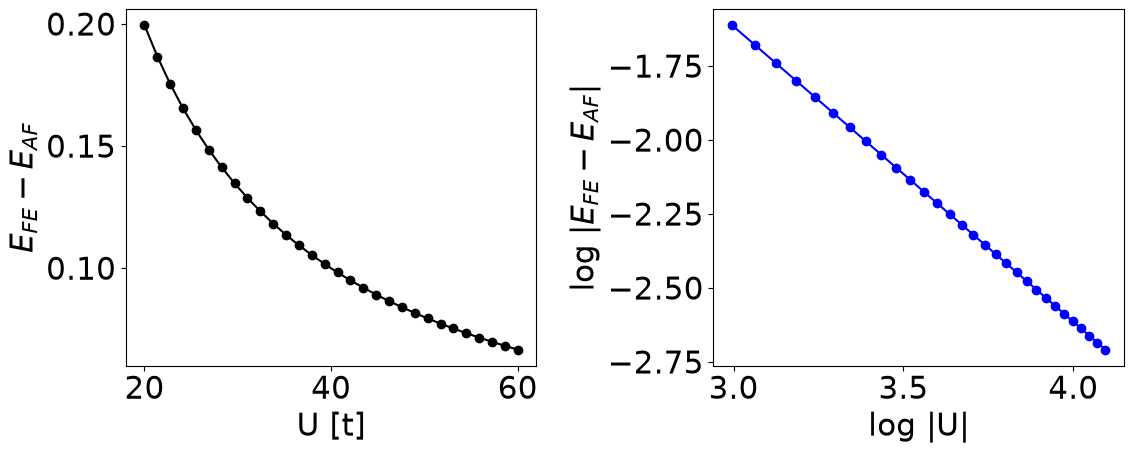

In [7]:
# let us now compute the energy difference as a function of U
from pyqula import geometry

fig = plt.figure(figsize=(12,5))
def get_energy_difference(U):
    g = geometry.bichain() # generate a chain with two sites per unit cell
    h = g.get_hamiltonian() # generate the Hamiltonian
    (hfe,efe) = h.get_mean_field_hamiltonian(U=U,return_total_energy=True,mf="ferro",mix=0.9) # FE
    (haf,eaf) = h.get_mean_field_hamiltonian(U=U,return_total_energy=True,mf="antiferro",mix=0.9) # AF
    return efe - eaf

Us = np.linspace(20.,60,30) # values of U considered

Et = [get_energy_difference(U) for U in Us] # energy differences

plt.subplot(1,2,1)
plt.plot(Us,Et,c="black",marker="o") # plot total energy VS value of U
plt.xlabel("U [t]") ; plt.ylabel("$E_{FE} - E_{AF}$")

plt.subplot(1,2,2)
plt.plot(np.log(np.abs(Us)),np.log(np.abs(Et)),c="blue",marker="o") # plot total energy VS value of U
plt.xlabel("log |U|") ; plt.ylabel("log |$E_{FE} - E_{AF}$|")

plt.tight_layout()

### Quiz
- Which state has the lowest energy?
- Discuss why the dependence of 1/U is observed in the energy differences between FE and AF configurations
- Compute this very same curve but going to lower values of U. Why does the 1/U behavior break down?

## Intermediate coupling regime and Stoner instability (***Core***)
Let us now show how there is a critical value of the electronic interaction to develop time-reversal symmetry breaking

The Stoner criterion $U\,g(E_F)>1$ sets the threshold interaction for spontaneous magnetism, where $g(E_F)$ is the non-interacting density of states at the Fermi level. Since $g(E_F)$ depends on filling, the critical $U_c\approx 1/g(E_F)$ shifts with doping — larger near a van Hove singularity, smaller in a nearly empty or full band.

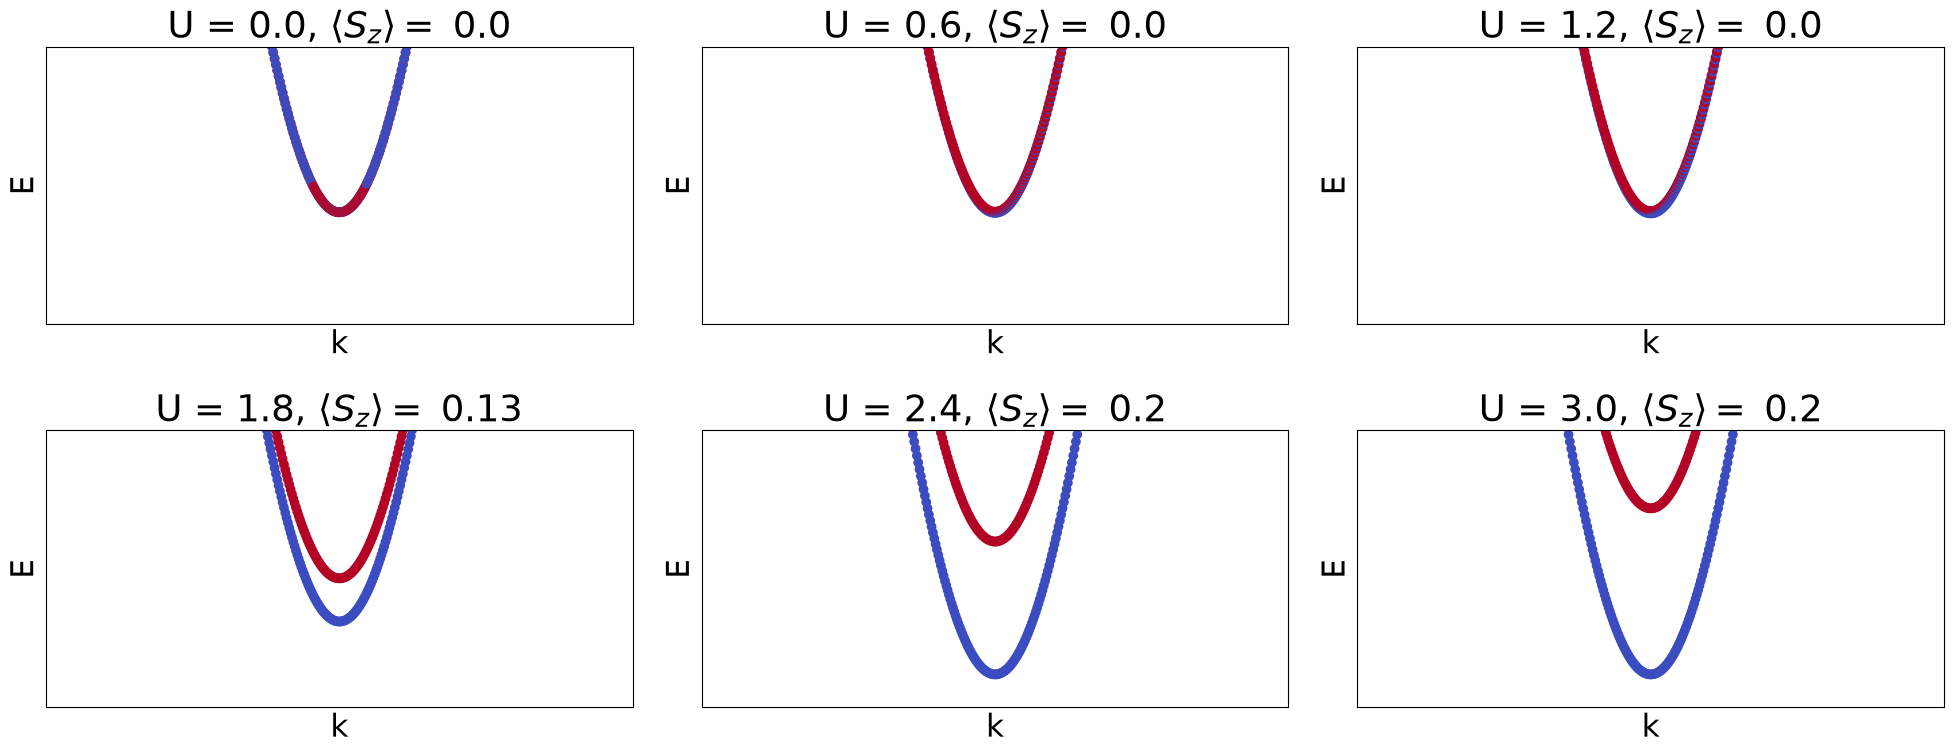

In [8]:
from pyqula import geometry
N = 6 # number of plots
Us = np.linspace(0.,3.0,N) # strengths of electronic interaction

ii = 1 # counter for the subplots
for U in Us:
    g = geometry.chain() # generate a chain
    h = g.get_hamiltonian() # generate the Hamiltonian
    h = h.get_mean_field_hamiltonian(U=U,filling=0.1,mf="ferro",mix=0.9,nk=300) # perform SCF
    plt.subplot(N//3,3,ii); ii += 1 
    (k,e,c) = h.get_bands(operator="sz") # compute band structure
    jz = np.mean(np.abs(h.get_vev("mz"))) # magnetization
    plt.title("U = "+str(np.round(U,2))+", $\\langle S_z \\rangle = $ "+str(np.round(jz,2))) # set the title
    plt.scatter(k,e,c=c) ; plt.yticks([]) ; plt.xticks([]) ; plt.ylim([-.5,.5]) ; plt.xlabel("k") ; plt.ylabel("E")
plt.tight_layout() # adjust the subplots

### Quiz
- Perform the calculation at a smaller filling (0.05 for example). Does the critical value increase or decrease?
- Perform the calculation at a bigger filling (0.2 for example). Does the critical value increase or decrease?
- Discuss why the critical value leading to magnetism changes

## Magnetism in flat bands (***Challenge***)
Let us now show the emergence of magnetic instabilities in a flat band system. For that, we will use a Lieb lattice, which can be viewed as a square lattice with a periodic vacancy (one out of every four sites removed), giving rise to a flat zero-energy mode

A flat band has a formally divergent density of states, $g(E_F)\to\infty$, so the Stoner criterion $Ug(E_F)>1$ is satisfied for arbitrarily small $U$ — flat-band systems are magnetic instabilities waiting to happen, in sharp contrast to the finite critical $U_c$ needed on a dispersive band.

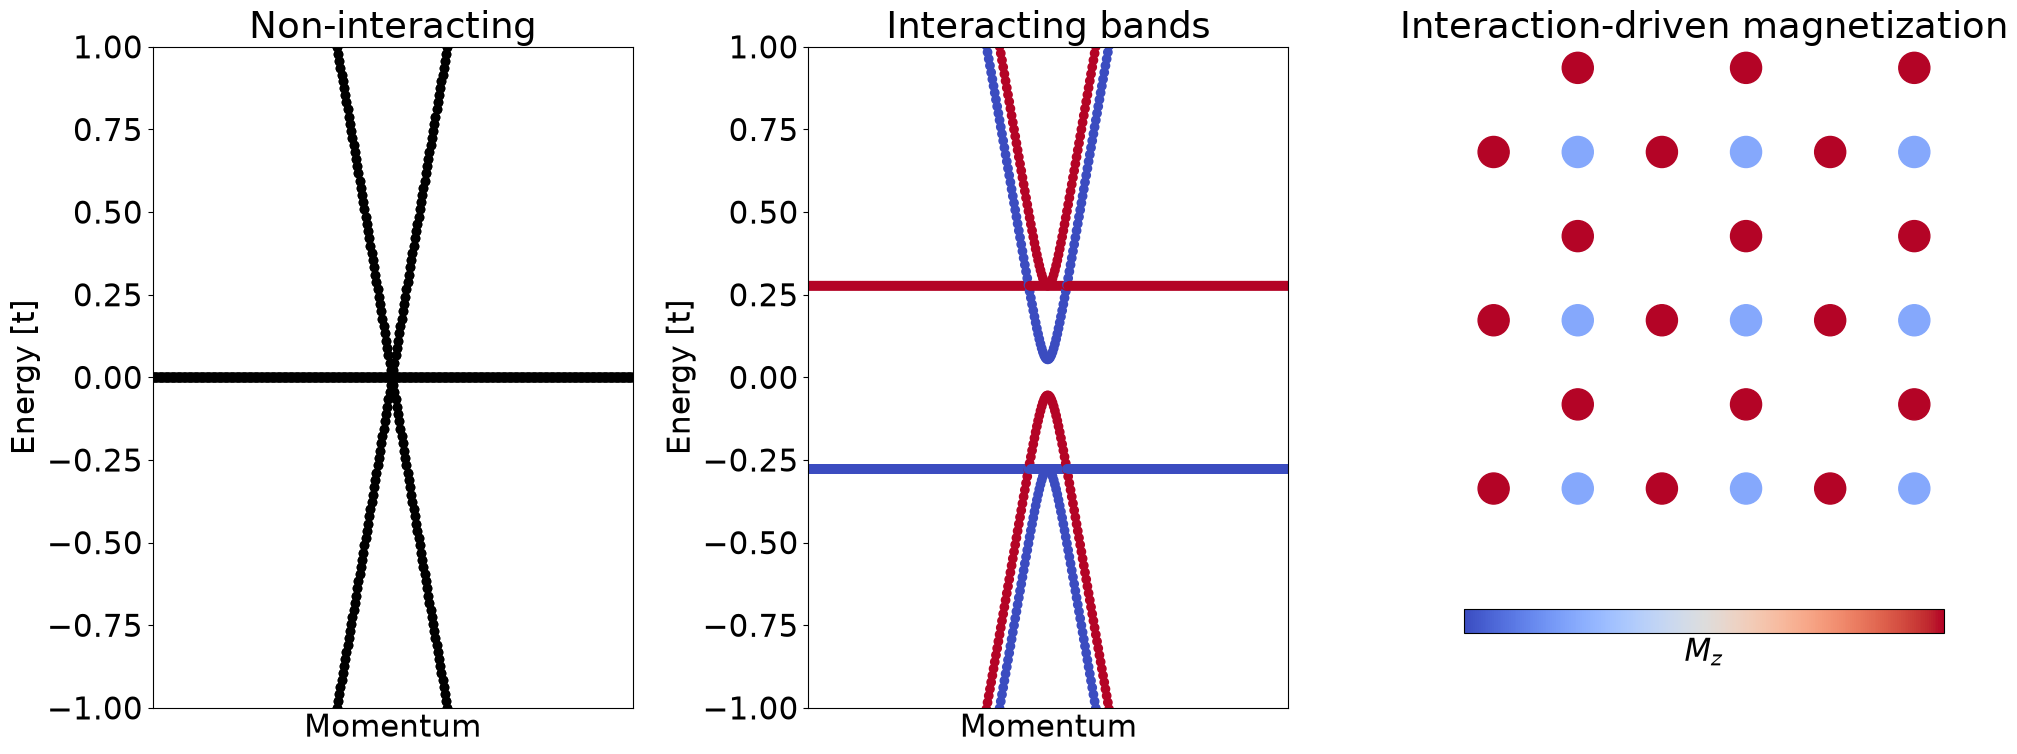

In [9]:
from pyqula import geometry
g = geometry.lieb_lattice() # generate a Lieb lattice

# first plot the non-interacting bands
plt.subplot(1,3,1) ; plt.title("Non-interacting")
h = g.get_hamiltonian() # generate the Hamiltonian
(k,e) = h.get_bands() # compute band structure
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]") ; plt.xticks([]) ; plt.ylim([-1.,1.])# plot
plt.xlim([min(k),max(k)])

# compute the mean-field Hamiltonian
U = 1.0 # value of the interaction
hscf = h.get_mean_field_hamiltonian(U=U,mix=0.9,mf="ferro") # perform mean-field

# plot the interacting bands
plt.subplot(1,3,2) ; plt.title("Interacting bands")
(k,e,c) = hscf.get_bands(operator="sz") # compute band structure
plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]") ; plt.xticks([]) ; plt.ylim([-1.,1.])# plot
plt.xlim([min(k),max(k)])

# plot the selfconsistent magnetization
plt.subplot(1,3,3) ; plt.title("Interaction-driven magnetization")
NS = 3
hs = hscf.get_supercell(NS) ; gs = hs.geometry ; mz = hs.extract("mz") # supercell geometry and Mz
plt.scatter(gs.r[:,0],gs.r[:,1],c=mz,vmin=-.1,vmax=.1,s=500) ; plt.axis("off") ; plt.axis("equal")
plt.colorbar(label="$M_z$",ticks=[],orientation="horizontal")
plt.tight_layout() # adjust subplots

### Quiz
- Change the value of the interaction U. Do you have an instability also for smaller U?
- Discuss how this can be understood in terms of the Stoner instability
- Take a different supercell N, and discuss if you observe flat bands and interaction-induced magnetization
- Replace the Lieb lattice by a Kagome lattice (geometry.kagome_lattice()), another lattice that hosts a flat band due to geometric frustration. Show whether flat bands and interaction-induced magnetization also appear there

## Non-collinear magnetism from competing interactions (***Challenge***)
Let us now include further neighbor hoppings, which promotes competing magnetic interactions

Competing first- and second-neighbor antiferromagnetic exchange (a lattice analogue of the $J_1$–$J_2$ Heisenberg chain) frustrates a simple collinear Néel state: neither sublattice pattern can satisfy both couplings simultaneously, and the energy is instead minimized by a spiral (non-collinear) spin texture with a pitch angle set by the ratio $J_2/J_1$.

(np.float64(-10.45),
 np.float64(10.45),
 np.float64(-0.05500000000000001),
 np.float64(0.05500000000000001))

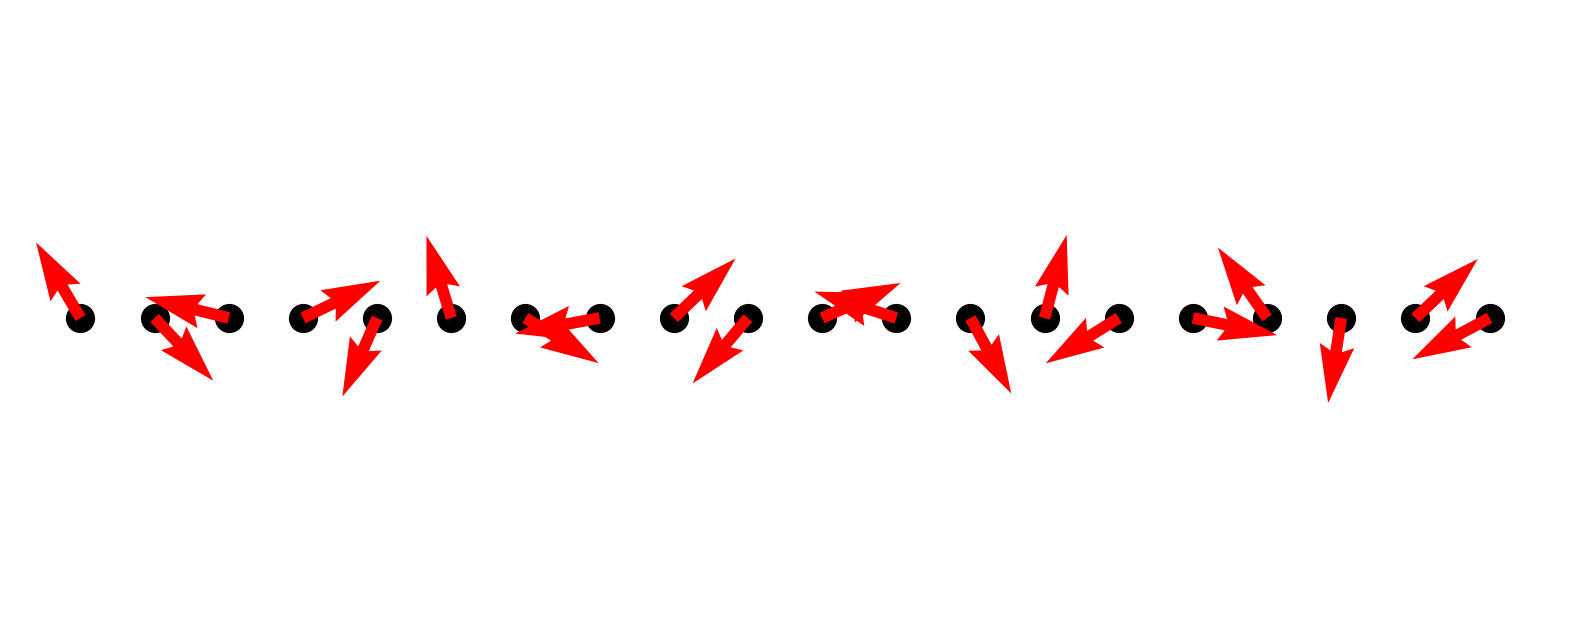

In [10]:
from pyqula import geometry
g = geometry.chain() # generate a chain 
g = g.get_supercell(20) ; g.dimensionality = 0 # use open boundaries, to avoid incommensurability issues
h = g.get_hamiltonian(tij=[1.,.6]) # generate the Hamiltonian

# generate the selfconsistent (SCF) Hamiltonian
U = 10. # strong Hubbard interaction
h = h.get_mean_field_hamiltonian(U=U,mf="XY",mix=0.9) # solve the interacting problem with a mean-field guess
mx = h.extract("mx") ; my = h.extract("my") ; x = h.geometry.r[:,0] ; y = h.geometry.r[:,1] # get magnetization
plt.scatter(x,y,c="black",s=400) ; plt.quiver(x,y,mx,my,color="red") ; plt.axis("off") ; plt.axis("equal") # plot magnetization

### Quiz
- Discuss why including second neighbor hopping gives rise to a non-collinear magnetic state
- Is there a long neighbor hopping that can be included that does not lead to non-collinearity? Include it and show that you recover the antiferromagnetic state

#### In the lab
- Non-collinear magnetism coming from competing interactions is observed in 2D materials, and in particular in the multiferroic monolayer NiI2
https://www.nature.com/articles/s41586-021-04337-x

## Non-collinear magnetism from spin-orbit coupling (***Challenge***)
We will now see that spin-orbit coupling is also able to generate a non-collinear magnetic texture

Rashba spin-orbit coupling generates an effective antisymmetric Dzyaloshinskii–Moriya interaction $\mathbf D_{ij}\cdot(\mathbf S_i\times\mathbf S_j)$ in the low-energy spin Hamiltonian, which favors neighboring spins canted at a fixed angle rather than parallel or antiparallel — producing the non-collinear spiral texture seen here, with a handedness set by the sign of the Rashba coupling.

(np.float64(-4.95),
 np.float64(4.95),
 np.float64(-0.05500000000000001),
 np.float64(0.05500000000000001))

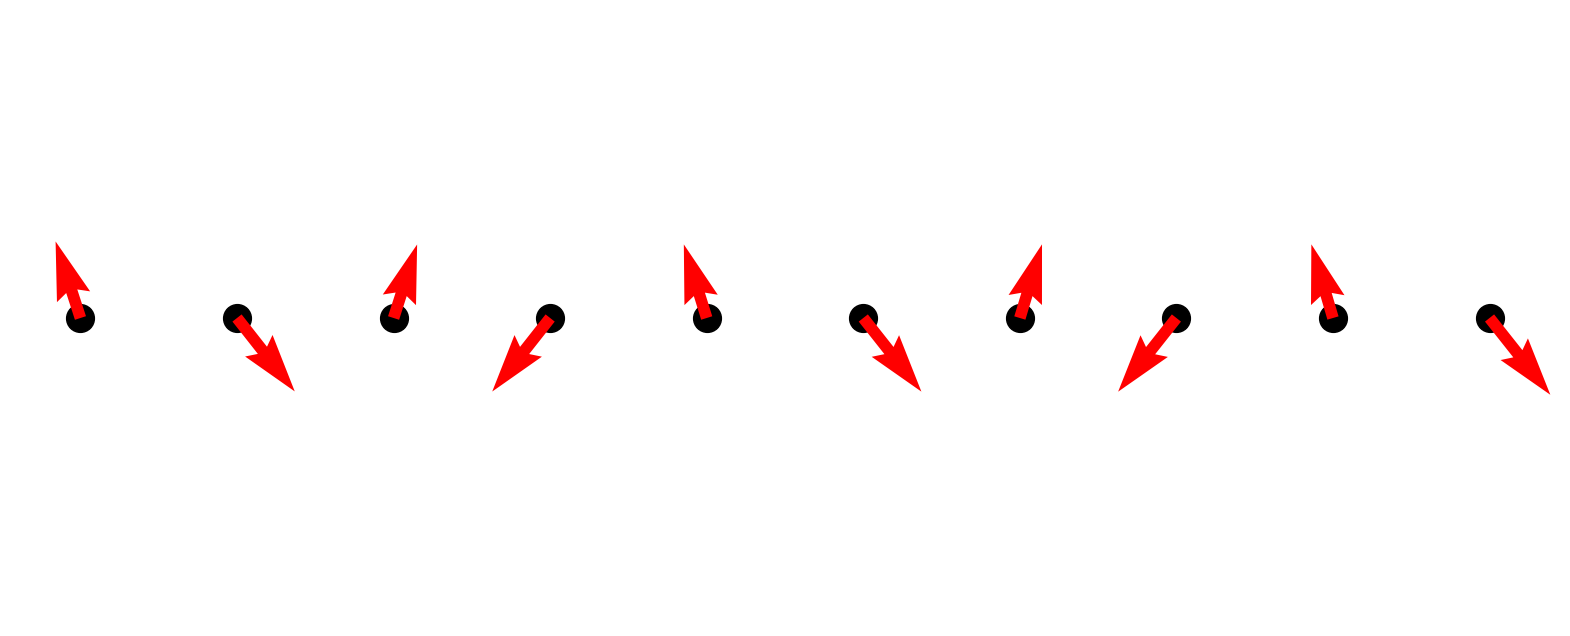

In [11]:
from pyqula import geometry
g = geometry.chain() # generate a chain 
g = g.get_supercell(10) ; g.dimensionality = 0 # use open boundaries, to avoid incommensurability issues
h = g.get_hamiltonian() # generate the Hamiltonian
h.add_rashba(1.) # add Rashba spin-orbit coupling

# generate the SCF Hamiltonian
U = 10. # strong Hubbard interaction
h = h.get_mean_field_hamiltonian(U=U,mf="XY",mix=0.9) # solve the interacting problem with a mean-field guess
mx = h.extract("mx") ; my = h.extract("my") ; x = h.geometry.r[:,0] ; y = h.geometry.r[:,1] # get magnetization
plt.scatter(x,y,c="black",s=400) ; plt.quiver(x,y,mx,my,color="red") ; plt.axis("off") ; plt.axis("equal") # plot magnetization

### Quiz
- Discuss why spin-orbit coupling gives rise to non-collinear magnetism
- What is the term in the spin Hamiltonian that Rashba SOC generates?
- What happens to the spin texture if the sign of the Rashba term is reversed? (Physically, it means flipping the sample upside down)

## Magnetic instabilities of the square lattice (***Core***)
Let us now address the magnetic instabilities of the square lattice

At half filling the bipartite square lattice Fermi surface is perfectly nested at $\mathbf Q=(\pi,\pi)$, so — just as in the 1D chain — the antiferromagnetic instability sets in at infinitesimally small $U$, in contrast to the honeycomb lattice of sessions 1–2, whose vanishing DOS at the Dirac point requires a finite $U_c$.

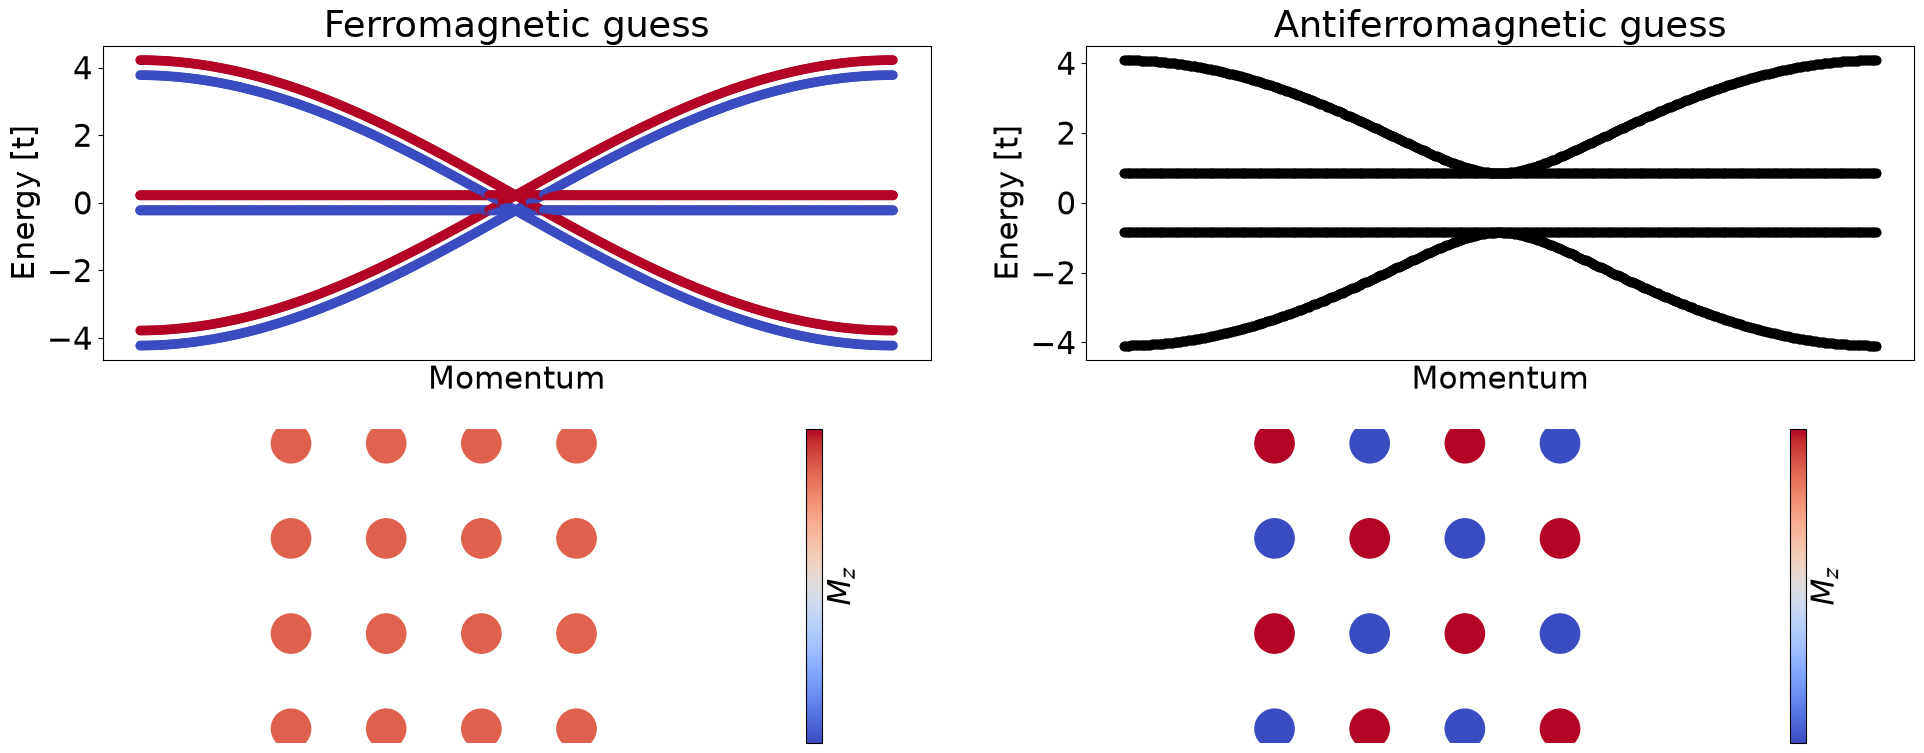

In [12]:
from pyqula import geometry
g = geometry.square_lattice_bipartite() # generate a bipartite square lattice
h = g.get_hamiltonian() # generate the Hamiltonian

# let us now add interactions, and compute the electronic structure
U = 3.0 # value of the local interaction

# first with a ferromagnetic guess
plt.subplot(2,2,1)
plt.title("Ferromagnetic guess")

hfe = h.get_mean_field_hamiltonian(U=U,mf="ferro",mix=0.9) # FE guess
(k,e,c) = hfe.get_bands(operator="sz") # compute band structure
plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]") ; plt.xticks([]) # plot

# plot z-component of the magnetization
hs = hfe.get_supercell(2) ; gs = hs.geometry ; mz = hs.extract("mz") # supercell geometry and Mz
plt.subplot(2,2,3)
plt.scatter(gs.r[:,0],gs.r[:,1],c=mz,vmin=-.3,vmax=.3,s=800) ; plt.yticks([]) ; plt.xticks([])
plt.axis("equal") ; plt.axis("off")
plt.colorbar(label="$M_z$",ticks=[])

# and with an antiferromagnetic guess
plt.subplot(2,2,2)
plt.title("Antiferromagnetic guess")
haf = h.get_mean_field_hamiltonian(U=U,mf="antiferro",mix=0.9) # AF guess
(k,e) = haf.get_bands() # compute band structure
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]") ; plt.xticks([]) # plot

# plot z-component of the magnetization
hs = haf.get_supercell(2) ; gs = hs.geometry ; mz = hs.extract("mz") # supercell geometry and Mz
plt.subplot(2,2,4)
plt.scatter(gs.r[:,0],gs.r[:,1],c=mz,vmin=-.3,vmax=.3,s=800) ; plt.yticks([]) ; plt.xticks([]) 
plt.axis("equal") ; plt.axis("off")
plt.colorbar(label="$M_z$",ticks=[])

plt.tight_layout()

### Quiz
- Which of the ferromagnetic or antiferromagnetic guesses converges to the lowest energy on the square lattice?
- How does the resulting magnetic order compare to the one found for the 1D chain?
- Increase the value of U, does the magnetic instability set in more easily than in the 1D chain?

## Non-collinear magnetic order from geometric frustration (***Challenge***)
We will now address 2D models that show non-collinear magnetism due to the geometric frustration of the lattice.

Antiferromagnetic order on the triangular lattice cannot simultaneously satisfy all three bonds of a triangle, so the mean-field ground state instead settles into the classic 120° non-collinear Néel order, with neighboring spins rotated by $120°$ around each triangular plaquette.

(np.float64(-4.124999999999999),
 np.float64(4.124999999999999),
 np.float64(-2.3815698604072066),
 np.float64(2.381569860407206))

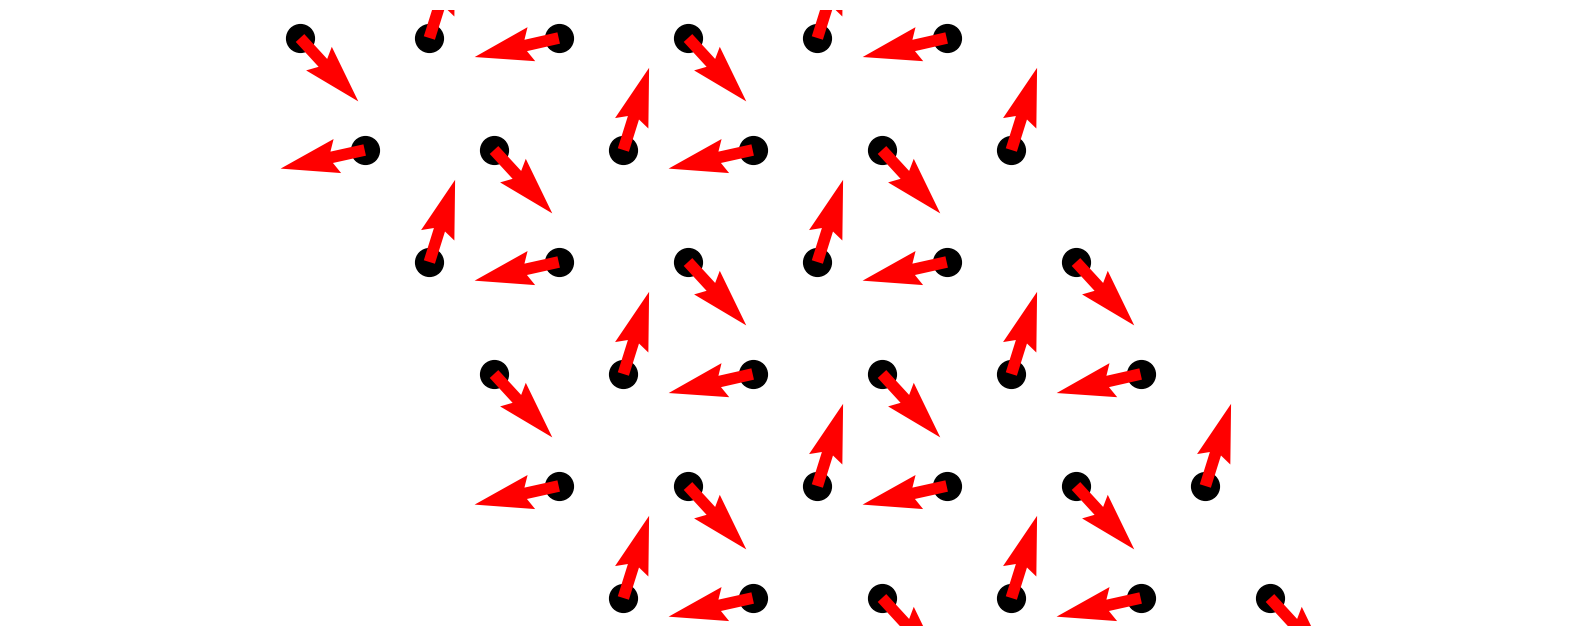

In [13]:
from pyqula import geometry
g = geometry.triangular_lattice() # generate a triangular lattice
g = g.get_supercell((3,3)) # make a supercell
h = g.get_hamiltonian() # generate the Hamiltonian

# generate the SCF Hamiltonian
U = 10. # strong Hubbard interaction
h = h.get_mean_field_hamiltonian(U=U,mf="XY",mix=0.9) # solve the interacting problem with a mean-field guess
hs = h.get_supercell(2) # generate a supercell
mx = hs.extract("mx") ; my = hs.extract("my") ; x = hs.geometry.r[:,0] ; y = hs.geometry.r[:,1] # get magnetization
plt.scatter(x,y,c="black",s=400) ; plt.quiver(x,y,mx,my,color="red")  # plot magnetization
plt.axis("equal") ; plt.axis("off")

### Quiz
- Plot the band structure for the SCF solution for the 3x3 supercell, and estimate its gap
- Plot the band structure for the SCF solution for the 1x1 supercell, and estimate its gap
- Can you infer which one is the lowest energy solution, and why?

### In the lab
- 1T-NbSe2 hosts a triangular lattice of magnetic sites, stemming from the charge density wave instability of the compound, each spin living in a charge density wave
https://www.science.org/doi/10.1126/sciadv.abi6339

## Electronic instabilities in graphene multilayers (***Challenge***)
Let us now address specific graphene multilayers, and show how magnetic instabilities can emerge due to their enhanced density of states

Increasing the number of ABC-stacked layers flattens the low-energy bands near the $K$ point (the surface-state-like bands of rhombohedral graphene), enhancing the density of states at charge neutrality. By the Stoner argument above, a larger $g(E_F)$ means these thicker stacks are more prone to interaction-driven electronic instabilities than a single graphene layer.

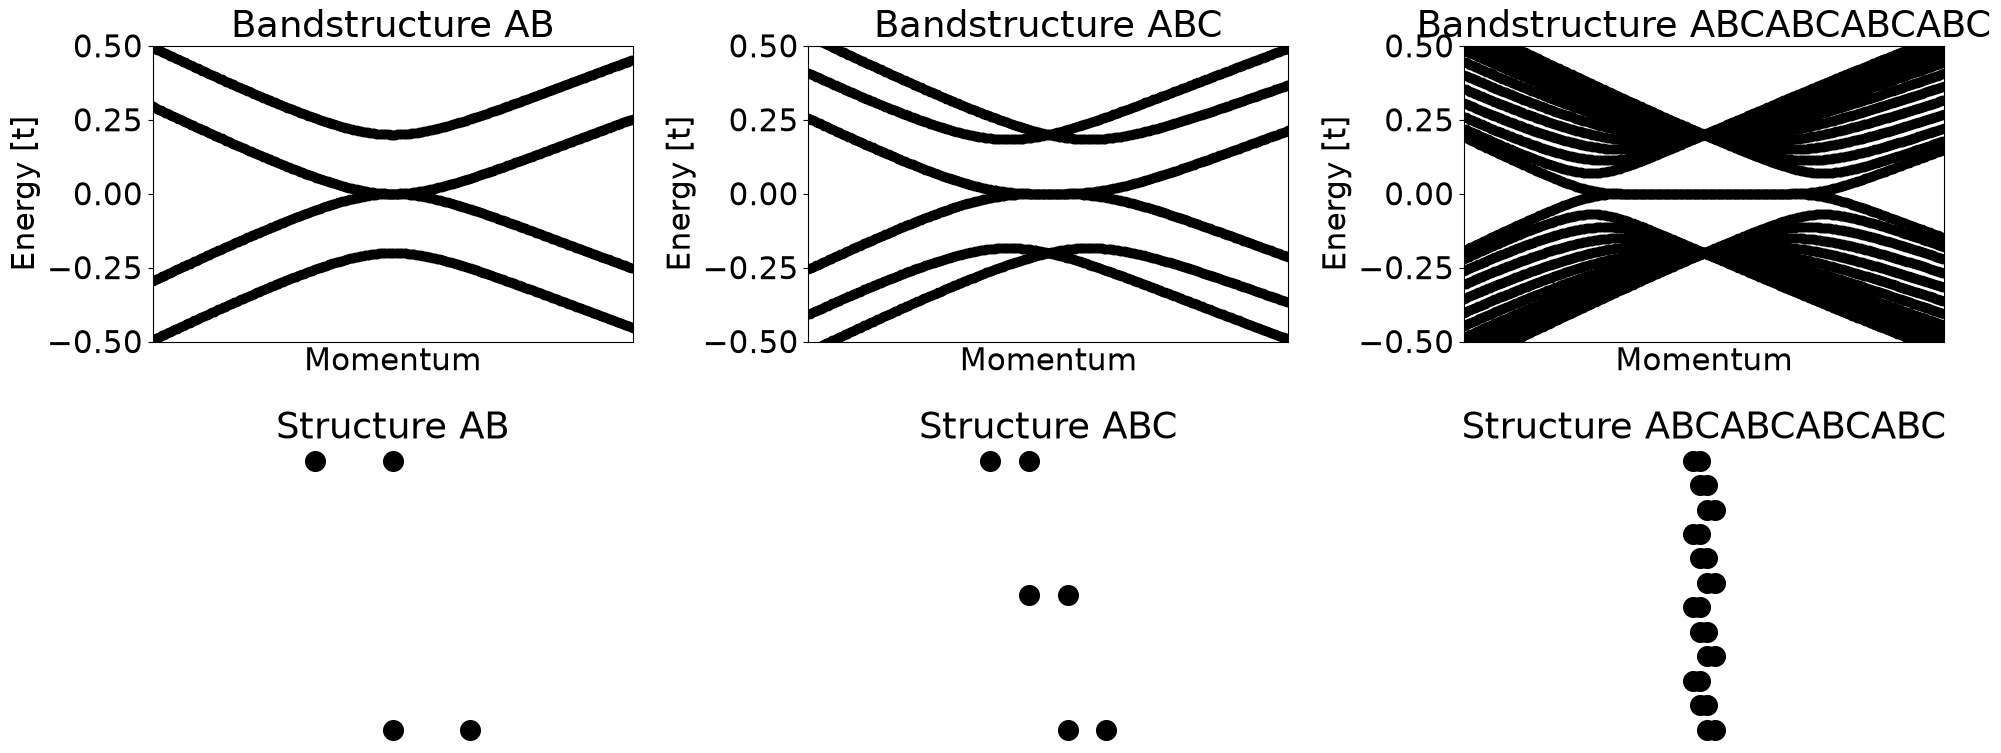

In [14]:
from pyqula import specialhamiltonian
mls = ["AB","ABC","ABCABCABCABC"] # graphene multilayers to consider
ii = 1 # counter
for m in mls: # loop over multilayers
    h = specialhamiltonian.multilayer_graphene(l=m,ti=0.2) # Hamiltonian of the graphene multilayer
    # make a small Kpath around the K point
    Kp = h.geometry.get_kpath(["K"])[0] ; kpath = [dk*Kp for dk in np.linspace(0.9,1.1,300)]
#    h = h.get_supercell(4) # make a supercell to see the bands easier
#    h.add_onsite(lambda r: r[2]*0.1/np.max(h.geometry.r[:,2])) # to add an electric field 
    (k,e) = h.get_bands(nk=300,kpath=kpath) # compute band structure
    plt.subplot(2,len(mls),ii) ; plt.title("Bandstructure "+m)
    plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]") ; plt.xticks([]) 
    plt.ylim([-.5,.5]) ; plt.xlim([min(k),max(k)])
    plt.subplot(2,len(mls),ii+len(mls)) ; plt.title("Structure "+m) ; gs = h.geometry
    plt.scatter(gs.r[:,0],gs.r[:,2],c="black",s=200) ; plt.axis("equal") ; plt.axis("off")
    ii += 1
    
plt.tight_layout() # tight layout

### Quiz
- Which of the three graphene multilayers above can have a stronger electronic instability? Discuss why
- Add an interlayer bias (as noted in the comment). What happens to the electronic structure?

## Magnetic symmetry breaking in graphene multilayers (***Challenge***)
We will now add interactions to a graphene multilayer, and see that those interactions open up a gap

With the enhanced density of states of the ABC-stacked multilayer, even a modest Hubbard $U$ satisfies the Stoner criterion and opens a gap via spontaneous order in the combined spin-sublattice channel probed by the plotted operator — the interacting counterpart of the enhanced-DOS instability discussed above.

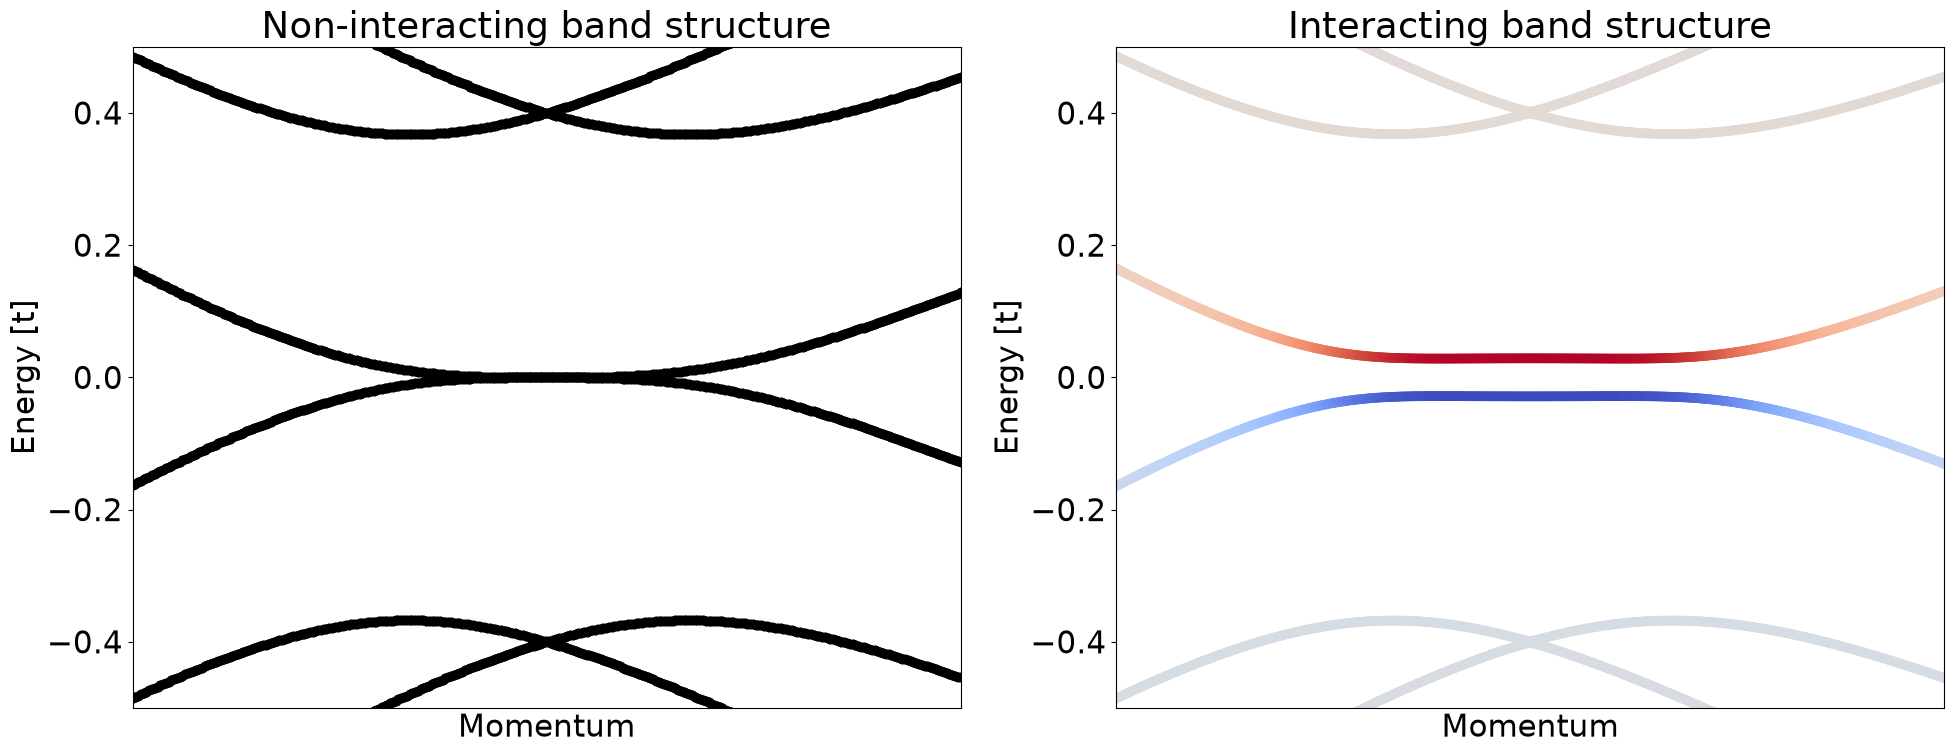

In [15]:
from pyqula import specialhamiltonian
h = specialhamiltonian.multilayer_graphene(l="ABC",ti=0.4) # Hamiltonian of the graphene multilayer
h.turn_spinful() 
# first plot the non-interacting bands
plt.subplot(1,2,1) ; plt.title("Non-interacting band structure")
# kpath around the K point
Kp = h.geometry.get_kpath(["K"])[0] ; kpath = [dk*Kp for dk in np.linspace(0.9,1.1,300)]
(k,e) = h.get_bands(nk=400,kpath=kpath) # compute band structure 
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]") 
plt.xticks([]) ; plt.ylim([-.5,.5]) ; plt.xlim([min(k),max(k)])

# compute the mean-field Hamiltonian
U = 2. # value of the interaction
hscf = h.get_mean_field_hamiltonian(U=U,filling=0.5,mix=0.9,mf="random",nk=30) # perform SCF

# plot the interacting bands
plt.subplot(1,2,2) ; plt.title("Interacting band structure")
op = hscf.get_operator("sz")*hscf.get_operator("sublattice")
(k,e,c) = hscf.get_bands(operator=op,nk=400,kpath=kpath) # compute band structure
plt.scatter(k,e,c=c) ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]") 
plt.xticks([]) ; plt.ylim([-.5,.5]) ; plt.xlim([min(k),max(k)])

plt.tight_layout() # adjust subplots

### Quiz
- Replace the multilayer by a single graphene monolayer. Do you still observe the electronic instability? Discuss why
- Add an out of plane electric field in the sample (add_onsite). What happens to the electronic instability?
- Change the doping of the system (filling), how does the electronic instability change?

#### In the lab
- Symmetry breaking in aligned multilayers has been observed experimentally for a variety of different thicknesses
https://www.science.org/doi/10.1126/science.aar6855

## Topological magnons in 2D magnets (***Challenge***)
Ordered 2D magnets feature magnon excitations, that can be effectively described with a single particle Hamiltonian. Here we will see how such magnon excitations can develop a topological gap, leading to edge states

Within linear spin-wave (Holstein–Primakoff) theory, magnon excitations above an ordered magnet obey an effective single-particle Hamiltonian, so the same topological machinery from session 3 applies directly: a Haldane-like second-neighbor term opens a topological gap in the magnon bands, producing chiral magnon edge states in a ribbon. Unlike electrons, magnon energies must be strictly positive — they are bosonic excitation energies above the ground state, not filled/empty fermionic levels.

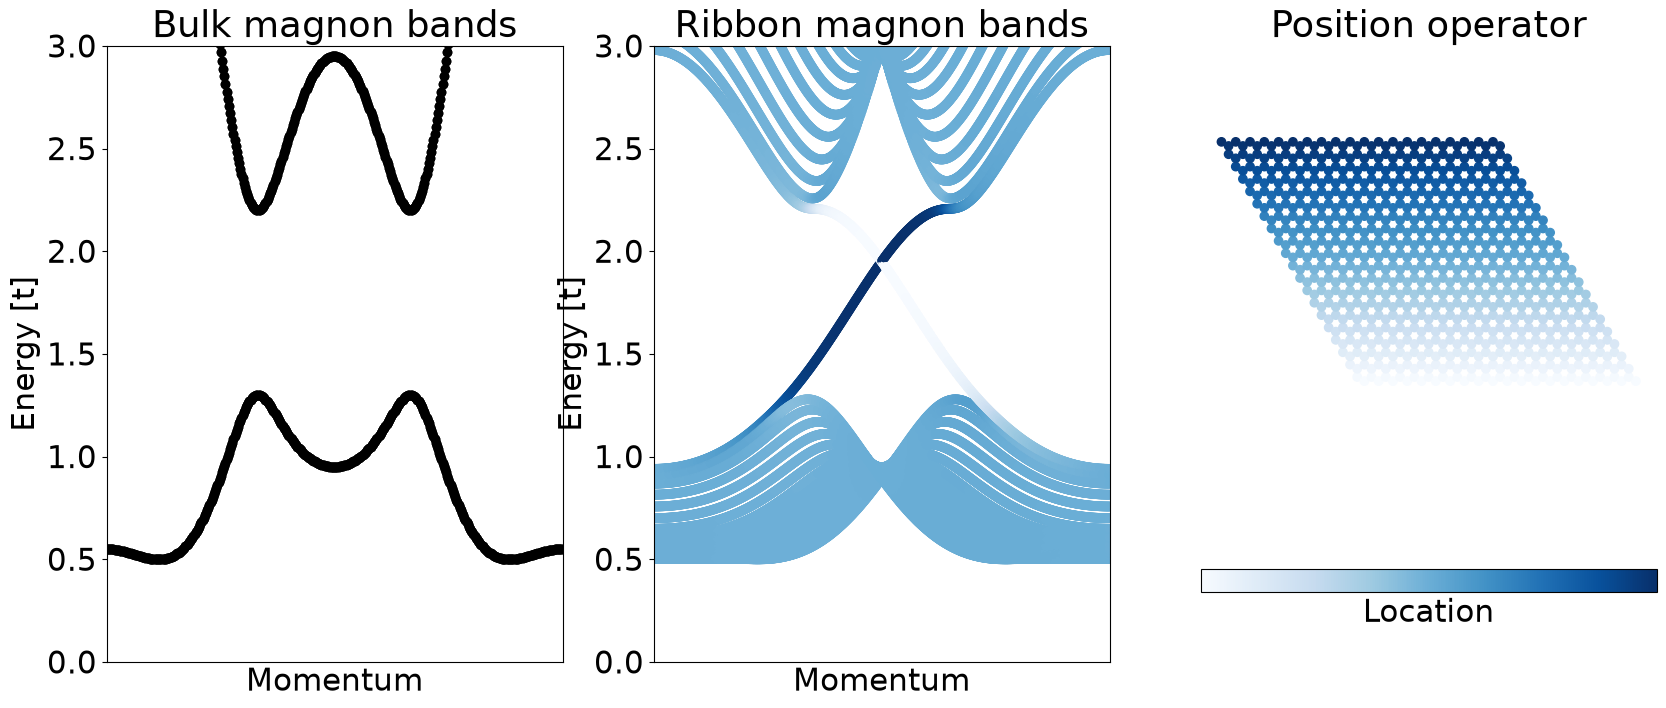

In [16]:
from pyqula import geometry, ribbon
g = geometry.honeycomb_lattice() # honeycomb lattice
h = g.get_hamiltonian(tij=[1.,0.2]) # generate the Hamiltonian
h.add_haldane(0.1) # add a coupling leadin to a topological gap
h.set_filling(0.0) ; h.add_onsite(0.5) # zero filling, and add a gap

# plot the bulk bands
plt.subplot(1,3,1) ; plt.title("Bulk magnon bands")
(k,e) = h.get_bands() # compute band structure
plt.scatter(k,e,c="black") ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]") 
plt.xticks([]) ; plt.xlim([min(k),max(k)]) ; plt.ylim([0.,3.])# plot

h = ribbon.bulk2ribbon(h,n=20)

# plot the bands
plt.subplot(1,3,2) ; plt.title("Ribbon magnon bands")
(k,e,c) = h.get_bands(operator="yposition") # compute band structure
plt.scatter(k,e,c=c,cmap="Blues") ; plt.xlabel("Momentum") ; plt.ylabel("Energy [t]") 
plt.xticks([]) ; plt.xlim([min(k),max(k)]) ; plt.ylim([0.,3.])# plot

# draw a ribbon with the position operator
gs = h.geometry.get_supercell(20) 
plt.subplot(1,3,3) ; plt.title("Position operator")
plt.scatter(gs.r[:,0],gs.r[:,1],c=gs.r[:,1],cmap="Blues") ; plt.axis("equal") ; plt.axis("off")
plt.colorbar(label="Location",ticks=[],orientation="horizontal")

### Quiz
- Change the value of the coupling opening a topological magnon gap (add_haldane). Do you still observe magnon edge states?
- Change the value of the second neighbor hopping (tij=[1.,t2]). Do you still observe magnon edge states?
- Discuss why the magnon eigenspectra should be positive

#### In the lab
- Signatures of magnon gaps at the Dirac point in CrI3 have been observed
https://journals.aps.org/prx/abstract/10.1103/PhysRevX.8.041028

## Many-body spin response functions (***Challenge***)
We will now see how magnon excitations appear directly from many-body response functions

The dynamical spin susceptibility $\chi(\mathbf q,\omega)=-i\int dt\, e^{i\omega t}\langle [S^+_{\mathbf q}(t),S^-_{-\mathbf q}(0)]\rangle$ probes collective spin excitations directly: its imaginary part traces out the dispersion of magnon-like modes as a function of momentum transfer $\mathbf q$ and energy transfer $\omega$, without needing to assume an ordered mean-field state beforehand.

In [17]:
from pyqula import geometry
import numpy as np

def get_bands_and_response(U=0.):
 g = geometry.bichain()
 h = g.get_hamiltonian()
 nk = 100
 hmf = h.copy() ; hmf.add_antiferromagnetism(0.5)
 h = h.get_mean_field_hamiltonian(U=U,nk=nk,mf=hmf,filling=0.5)
 qs = np.linspace(0.,.5,50) # qvectors
 energies=np.linspace(.0,5.,200) # energies
 (kb,eb) = h.get_bands()
 chimap = []
 def f(q):
    return h.get_spinchi_ladder(q=[q,0.,0.],nk=nk,energies=energies,delta=3e-2,
            imode="mesh")
 out = [f(q) for q in qs] # compute all
 for o in out: # loop over qvectors
    es,chis = o[0],o[1]
    cs = [np.trace(c).imag for c in chis]
    cs = np.array(cs)/np.mean(cs)
    chimap.append(cs) # store 
 return (qs,energies,chimap),(kb,eb)

def plot_bands_and_response(data,**kwargs):
   (qs,energies,chimap),(kb,eb) = data
   fig = plt.figure(figsize=(14,5))
   plt.subplot(1,2,1) ; plt.title("Bandstructure")
   plot_bands(kb,eb)
   plt.subplot(1,2,2) ; plt.title("Spin response")
   plot_response(qs,energies,chimap,**kwargs)
   plt.tight_layout()

def plot_bands(kb,eb):
   import matplotlib.pyplot as plt
   plt.scatter(kb,eb,c="black")
   plt.ylabel("Energy [t]") ; plt.xlabel("Momentum") ; plt.xticks([]) ; plt.xlim([min(kb),max(kb)])


def plot_response(qs,energies,chimap,emax=None):
   chimap = np.array(chimap) ; chimap = np.abs(chimap) 
   chimap = chimap/np.max(chimap)
   vmax = np.percentile(chimap,99)
   chimap[chimap>vmax] = vmax # saturate
   plt.contourf(qs,energies,chimap.T,levels=100,cmap="Blues_r")
   if emax is not None: plt.ylim([0.,emax])
   plt.colorbar(label="Spin response",ticks=[])
   plt.xlabel("q-vector [$\\pi$]") ; plt.ylabel("$\\omega$")


## Non-interacting limit
We will first compute the spin-spin response in the non-interacting limit

With $U=0$ there is no ordered moment and no true magnon, only the particle-hole continuum of independent single-particle spin-flip excitations $\mathrm{Im}\,\chi_0(\mathbf q,\omega)$ — broad in energy at each $\mathbf q$, in contrast to the sharp collective mode that appears once interactions are switched on.

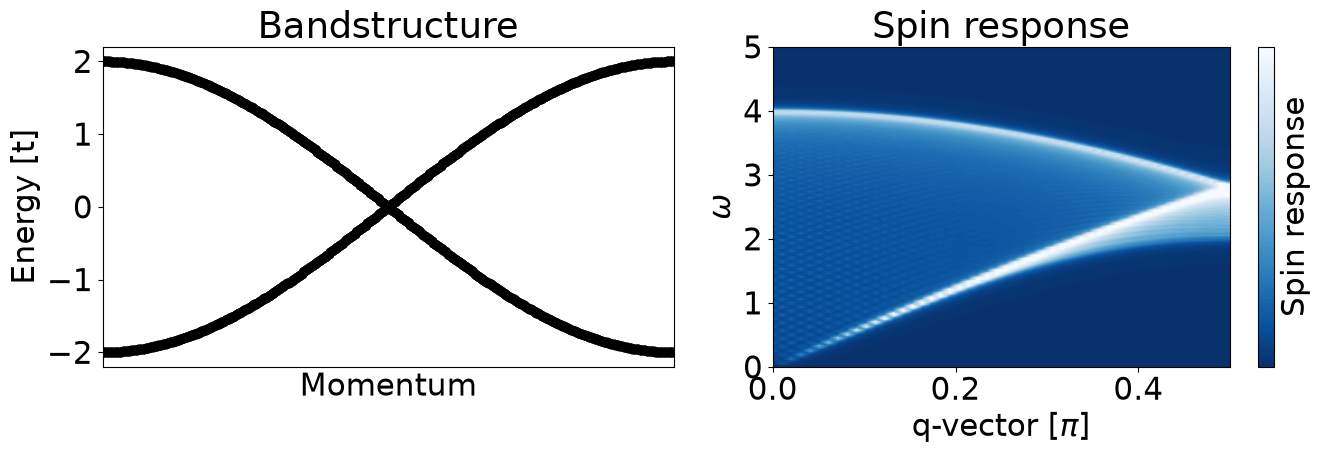

In [18]:
data = get_bands_and_response(U=0.) # get the data
plot_bands_and_response(data) # plot everything

### Quiz
- Why is there a continuum in the spin-response?
- Take a large interaction U, what happens to the band structure and why?

## Spin response for increasing interaction

Turning on $U$ redistributes spectral weight from the broad particle-hole continuum into a sharp collective magnon pole (an RPA resummation of the response function), whose energy signals the same Stoner instability discussed earlier: as $U$ approaches the critical interaction, this pole softens toward $\omega=0$.

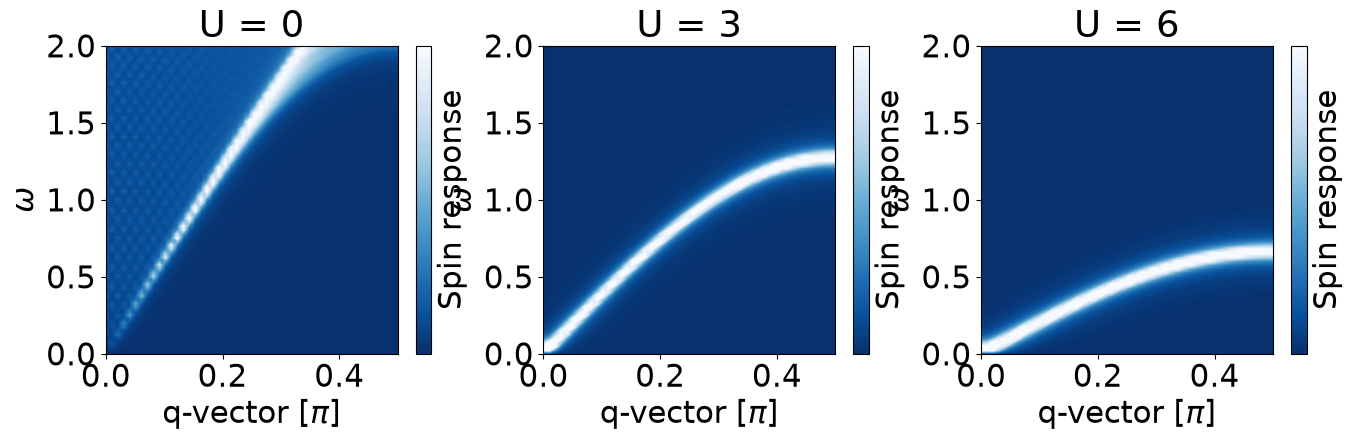

In [19]:
Us = [0.,3.,6.] # values of U
iU = 1
plt.figure(figsize=(16,4))
for U in Us:
    data_response = get_bands_and_response(U=U)[0] # get the data
    plt.subplot(1,len(Us),iU) ; plt.title("U = "+str(round(U))) ; iU += 1
    plot_response(*data_response,emax=2.)


### Quiz
- Increase the interaction even more, what happens to the magnon branch and why?